(dro_medical_app:title)=
# Medical Appointment Scheduling under Cross Moment Ambiguity

We consider a medical appointment scheduling problem described in {cite:ps}`Bertsimas_Sim_Zhang2019adaptive`, where $N$ patients arrive at their stipulated schedule and may have to wait in a queue to be served by a physician. The patients' consultation times, denoted by $\tilde{\pmb{z}}\in\mathbb{R}^N$, are uncertain and their arrival schedules in terms the assigned consultation lengths $\pmb{x}\in\mathbb{R}^N$ must be determined at the first stage. A distributionally robust optimization model presented below is used to minimize the worst-case expected total cost of patient's waiting and physician's overtime,

```{math}
\begin{aligned}
\min~&\sup\limits_{\mathbb{P}\in\mathcal{F}}\mathbb{E}_{\mathbb{P}}\left[\sum\limits_{j=1}^Ny_i(\tilde{\pmb{z}}, \tilde{\pmb{u}}) + c y_{N+1}(\tilde{\pmb{z}}, \tilde{\pmb{u}})\right] \\
\text{s.t.}~&y_{j+1}(\pmb{z}, \pmb{u}) - y_{j}(\pmb{z}, \pmb{u}) + x_{j} \geq z_{j} &&\forall (\pmb{z}, \pmb{u})\in\mathcal{Z},~\forall j\in [N] \\
&\pmb{y}(\pmb{z}, \pmb{u}) \geq \pmb{0} &&\forall (\pmb{z}, \pmb{u}) \in \mathcal{Z} \\
&y_j\in \overline{\mathcal{A}}(\{\{1\}\}, [N+1]) &&\forall j \in [N] \\
&\sum\limits_{j=1}^N x_j \leq T \\
&\pmb{x} \in \mathbb{R}_+^N,
\end{aligned}
```

where the second-stage decision $y_j$ denotes the waiting time of patient $j$, with $j\in[N]$ and $y_{N+1}$ represents the overtime of the physician. The ambiguity set $\mathcal{F}$ is formulated below for capturing cross moment information,

```{math}
\mathcal{F}=\left\{
\mathbb{P}\in\mathcal{P}\left(\mathbb{R}^N\times \mathbb{R}^{N+1}\right) \left|
\begin{array}{ll}
(\tilde{\pmb{z}}, \tilde{\pmb{u}}) \sim \mathbb{P} \\
\mathbb{P}[\tilde{\pmb{z}}\in\mathcal{Z}] = 1 \\
\mathbb{E}_{\mathbb{P}}[\tilde{\pmb{z}}] = \pmb{\mu} \\
\mathbb{E}_{\mathbb{P}}[\tilde{u}_j] \leq \sigma_j^2 &\forall j \in [N]\\
\mathbb{E}_{\mathbb{P}}[\tilde{u}_{N+1}]\leq \pmb{1}^{\top}\pmb{\Sigma}\pmb{1}
\end{array}
\right.
\right\},
```

with the support $\mathcal{Z}$ defined as

```{math}
\mathcal{Z} = \left\{
(\tilde{\pmb{z}}, \tilde{\pmb{u}}): 
\begin{array}{ll}
\pmb{z} \geq \pmb{0} \\
(z_j - \mu_j)^2 \leq u_j &\forall j \in [N] \\
\left(\sum\limits_{j=1}^N(z_j - \mu_j)\right)^2 \leq u_{N+1}
\end{array}
\right\}.
```

According to {cite:ps}`Bertsimas_Sim_Zhang2019adaptive`, parameters of the model are specified as:
- $N=8$ as the number of patients;
- $c=2.0$ as the unit cost of physician overtime;
- $\pmb{\mu}=\mathbb{R}^N$ as the mean consultation time of all patients, each $\mu_i$ is randomly generated uniformly over $[30,~60]$;
- $\pmb{\sigma}\in\mathbb{R}^N$ as the standard deviations of the consultation times, each $\sigma_i=\mu_j\epsilon_j$ with $\epsilon_j$ randomly generated uniformly over $[0,~0.3]$;
- $T$ as the regular working hours of the physician, expressed as $T=\sum_{i=1}^N\mu_i + 0.5\sqrt{\sum_{i=1}^N\sigma_i^2}$;
- Covariance matrix $\pmb{\Sigma}$ of the random consultation time, with each element to be

```{math}
\left[\pmb{\Sigma}_{ij}\right] = \begin{cases}
0.25\sigma_i\sigma_j &\text{if }i\not=j \\
\sigma_j^2 &\text{otherwise.}
\end{cases}
```

In [1]:
import numpy as np

np.random.seed(1)

N = 8
c = 2
mu = 30 + 30*np.random.rand(N)
sigma = mu * 0.3*np.random.rand(1, N)

T = mu.sum() + 0.5*((sigma**2).sum())**0.5

mul = np.diag(np.ones(N))*(1-0.25) + np.ones((N, N))*0.25
Sigma = (sigma.T @ sigma) * mul

In the distributionally robust model, each wait-and-see decision $y_j(\pmb{z}, \pmb{u})$ is defined to follow the affine decision rule $\overline{\mathcal{A}}\left(\{\{1\}\}, [2N+1]\right)$, which implies that each $y_j$ affinely depends on random variables $\pmb{z}\in\mathbb{R}^N$ and $\pmb{u}\in\mathbb{R}^{N+1}$. The corresponding RSOME model is implemented and solved as follows.

In [4]:
from rsome import dro
from rsome import E
import rsome as rso

model = dro.Model()
z = model.rvar(N)
u = model.rvar(N+1)

fset = model.ambiguity()
fset.suppset(z >= 0,
             rso.square(z - mu) <= u[:-1],
             rso.square((z-mu).sum()) <= u[-1])
fset.exptset(E(z) == mu, E(u)[:-1] <= sigma**2,
             E(u)[-1] <= Sigma.sum())

x = model.dvar(N)
y = model.dvar(N+1)
y.adapt(z)
y.adapt(u)

model.minsup(E(y[:-1].sum() + c*y[-1]), forall=fset)
model.st(y[1:] - y[:-1] + x >= z, y >= 0)
model.st(x.sum() <= T, x >= 0)

model.solve()

Being solved by ECOS 2.0.14...
Solution status: Optimal solution found
Running time: 0.0485s


The optimal objective value is shown below.

In [5]:
print(f'Objective: {model.get():.4f}')

Objective: 91.3042


We can also retrieve the optimal solution through calling `x.get()` and visualize the results.

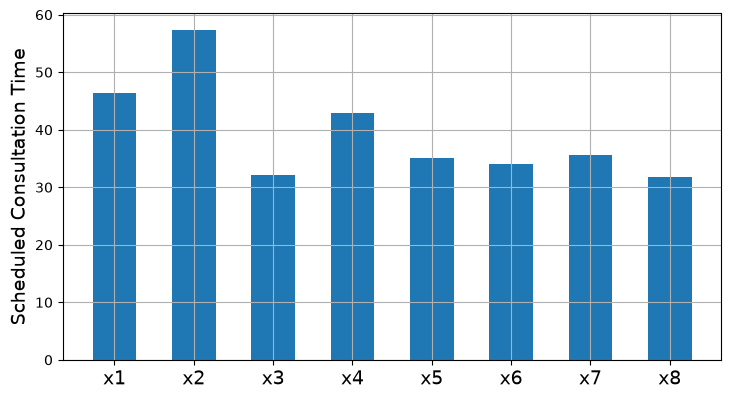

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(8.5, 4.5))
labels = [f'x{i+1}' for i in range(N)]
plt.bar(labels, x.get(), width=0.55)
plt.ylabel('Scheduled Consultation Time', fontsize=14)
plt.xticks(fontsize=14)
plt.grid()
plt.show()

<br>
<br>

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```